# Predicting Seasonal Paddy Production in Sri Lanka
### MSc Applied Machine Learning | Final assignment
**Student:** W.D.N. De Silva  
**Student ID:** 269096C  
**Module:** IT5514 – Applied Machine Learning

**Compared algorithm:** Explainable Boosting Machine (EBM), Random Forest, XGBoost, CatBoost and LightGBM.  
**Prediction Target:** Production_t(season harvest production in tonnes agaists district.)    

## 1. Problem Description
Paddy cultivation plays an important role in Sri Lanka's agriculture and food security. However, paddy production varies across districts and cultivation seasons due to factors such as rainfall, temperature, cultivated area, and previous harvest performance. These variations make accurate production estimation challenging and affect agricultural planning.

**Aim:** This study aims to predict district-level paddy production in Sri Lanka using historical agricultural and weather. And check how does Explainable Boosting Machine (EBM) compare with Random Forest, XGBoost, CatBoost and LightGBM on this Sri Lankan tabular regression problem.Statistics, Sri Lanka.

**Data Source:** Department of Census and Statistics (DCS), Sri Lanka, for the agricultural/paddy statistics. (Official source: https://www.statistics.gov.lk/Agriculture/StaticalInformation/PaddyStatistics.) The DCS describes its district-level crop-cutting survey and production statistics and the Open Meteo Weather Forecasting site for the weater discrict wise statistics. (Official source:https://open-meteo.com/en/features)

Combined the both data source and create the final paddy_weather_final.xlsx, 660 district-season observations and 15 columns, covering 2010–2023 and 25 districts.

**Why EBM:** Explainable Boosting Machine (EBM) is selected because it can capture complex, nonlinear relationships while providing clear explanations of how individual factors influence predictions. Its performance is compared with Random Forest, XGBoost, CatBoost, and LightGBM to evaluate both prediction accuracy and explainability.

**Important real-world limitation:** The features include measured weather for the whole cultivation season. Therefore, this project estimates production when those weather measurements are available; it is not a reliable before-planting forecast.

## 2. Import Libraries and Load the Dataset

In [25]:
%pip install -q pandas openpyxl numpy matplotlib seaborn scikit-learn xgboost catboost lightgbm shap lime interpret-core

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from interpret.glassbox import ExplainableBoostingRegressor

RANDOM_SEED = 42
# The workbook lives in data/raw/ at repository level. These alternatives also support Colab.
file_candidates = [
    Path('data/raw/paddy_weather_final.xlsx'),
    Path('../data/raw/paddy_weather_final.xlsx'),
    Path('paddy_weather_final.xlsx'),
    Path('/content/paddy_weather_final.xlsx'),
    Path('/mnt/data/paddy_weather_final.xlsx'),
]
data_file = next((p for p in file_candidates if p.exists()), None)
if data_file is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        data_file = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Place paddy_weather_final.xlsx inside the repository data/raw/ folder or upload it in Colab.')

df = pd.read_excel(data_file).sort_values(['Year', 'Season', 'District']).reset_index(drop=True)
print('File:', data_file.name, '| Shape:', df.shape)
display(df.head())

Saving paddy_weather_final.xlsx to paddy_weather_final (1).xlsx
File: paddy_weather_final (1).xlsx | Shape: (660, 15)


,District,Year,Season,SownArea_ha,PreviousYearProduction_t,SeasonRainfall_mm,SeasonMeanTemp_C,SeasonMeanMaxTemp_C,SeasonMeanMinTemp_C,SeasonET0_mm,SeasonMeanRadiation_MJ_m2_day,SeasonSunshineHours,RainyDays,HotDays35C,Production_t
0,Ampara,2010,Yala,59255,214941.0,441.5,28.652288,32.567974,25.890850,703.25,20.599412,1575.511911,87,1,275913
1,Anuradhapura,2010,Yala,22887,63275.0,417.8,27.627451,31.671895,25.130719,677.59,18.868627,1519.902664,77,4,89625
2,Badulla,2010,Yala,12665,31671.0,662.8,24.824837,29.235948,21.473203,643.91,19.134967,1509.083747,90,0,48224
3,Batticaloa,2010,Yala,20901,59227.0,318.4,29.117647,32.590196,26.509150,735.39,20.705359,1564.316258,61,4,73906
4,Colombo,2010,Yala,2656,9200.0,1419.5,26.800654,29.193464,25.170588,502.11,16.354314,1331.746814,150,0,7244


The dataset contains 660 district-season rows and 15 columns, including 25 districts and observations from 2010–2023.

## 3. Dataset Understanding and Data Quality

In [27]:
print('Columns:', df.columns.tolist())
print('Observations:', len(df), '| Districts:', df['District'].nunique(), '| Years:', sorted(df['Year'].unique()))
print('Seasons:', df['Season'].value_counts().to_dict())
print('Missing values by feature:')
display(df.isna().sum().to_frame('Missing values'))
print('Repeated Year + District + Season keys:', df.duplicated(['Year','District','Season']).sum())
print('Target description (tonnes):')
display(df['Production_t'].describe().to_frame('Production_t'))

if df['Production_t'].isna().any():
    raise ValueError('The target has missing values. Investigate before training.')

Columns: ['District', 'Year', 'Season', 'SownArea_ha', 'PreviousYearProduction_t', 'SeasonRainfall_mm', 'SeasonMeanTemp_C', 'SeasonMeanMaxTemp_C', 'SeasonMeanMinTemp_C', 'SeasonET0_mm', 'SeasonMeanRadiation_MJ_m2_day', 'SeasonSunshineHours', 'RainyDays', 'HotDays35C', 'Production_t']
Observations: 660 | Districts: 25 | Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Seasons: {'Yala': 336, 'Maha': 324}
Missing values by feature:


,Missing values
District,0
Year,0
Season,0
SownArea_ha,0
PreviousYearProduction_t,5
SeasonRainfall_mm,0
SeasonMeanTemp_C,0
SeasonMeanMaxTemp_C,0
SeasonMeanMinTemp_C,0
SeasonET0_mm,0


Repeated Year + District + Season keys: 0
Target description (tonnes):


,Production_t
count,660.000000
mean,80952.072727
std,93071.455100
min,274.000000
25%,21210.250000
50%,40606.000000
75%,100308.250000
max,530356.000000


The output showes five missing values, all in PreviousYearProduction_t, and no duplicate district/year/season combinations. We keep the records and fill the missing input values using training-only medians.

## 4. Exploratory Data Analysis (EDA)
These graphs help us understand the production figures before selecting a model:

- **Distribution chart:** Are most district-season production values small or large? Are there unusual values?
- **Yearly totals:** Does recorded production change across years? These totals describe the dataset, not necessarily an official national series.
- **Scatter plot:** Do larger cultivated areas generally produce more paddy?
- **Season box plot:** How do Maha and Yala production values differ?
- **Correlation heatmap:** Which numeric variables tend to move together?

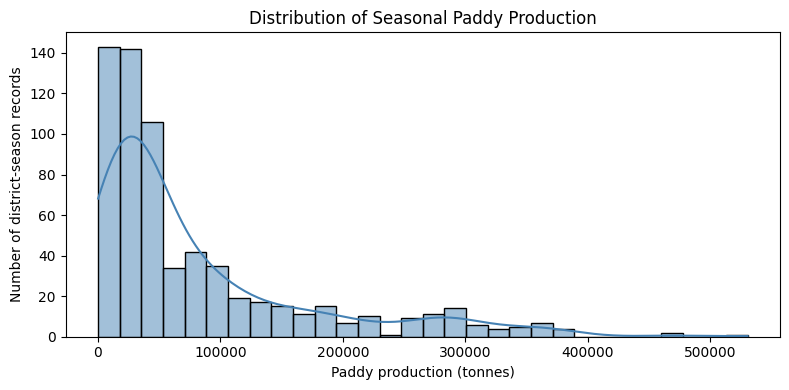

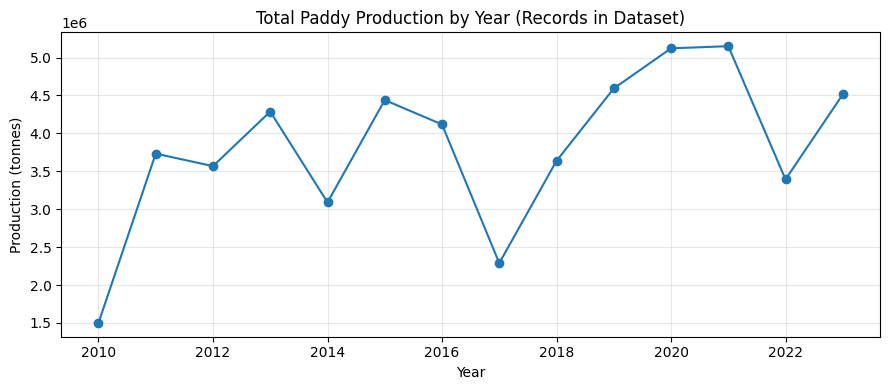

In [28]:
# Graph 1: Distribution of paddy production.
plt.figure(figsize=(8, 4))
sns.histplot(df['Production_t'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Seasonal Paddy Production')
plt.xlabel('Paddy production (tonnes)')
plt.ylabel('Number of district-season records')
plt.tight_layout()
plt.show()

# Graph 2: National production totals by year (sum of the available records).
yearly = df.groupby('Year')['Production_t'].sum()
plt.figure(figsize=(9, 4))
plt.plot(yearly.index, yearly.values, marker='o')
plt.title('Total Paddy Production by Year (Records in Dataset)')
plt.xlabel('Year')
plt.ylabel('Production (tonnes)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

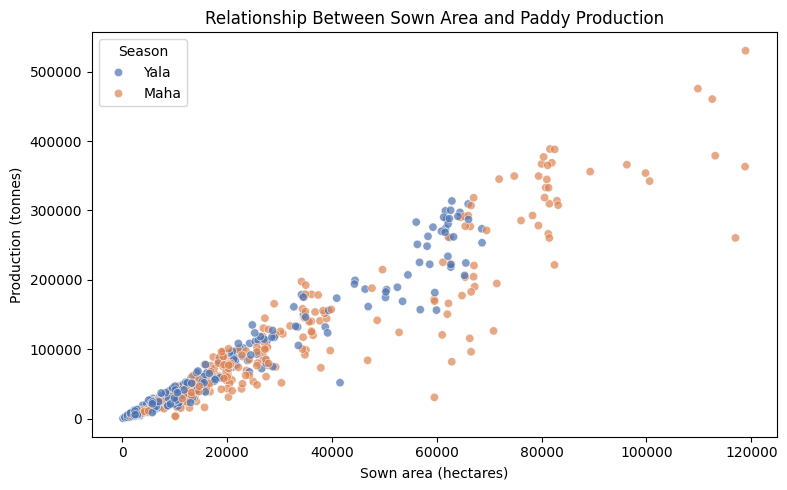

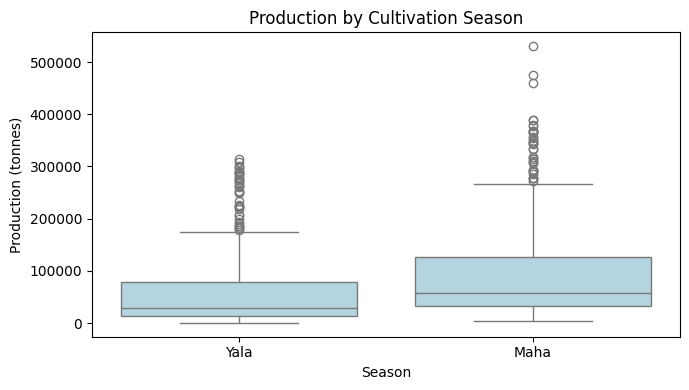

In [29]:
# Graph 3: Cultivated area against production.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='SownArea_ha', y='Production_t', hue='Season', alpha=0.7, palette='deep')
plt.title('Relationship Between Sown Area and Paddy Production')
plt.xlabel('Sown area (hectares)')
plt.ylabel('Production (tonnes)')
plt.tight_layout()
plt.show()

# Graph 4: Maha versus Yala production.
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='Season', y='Production_t', color='lightblue')
plt.title('Production by Cultivation Season')
plt.ylabel('Production (tonnes)')
plt.tight_layout()
plt.show()

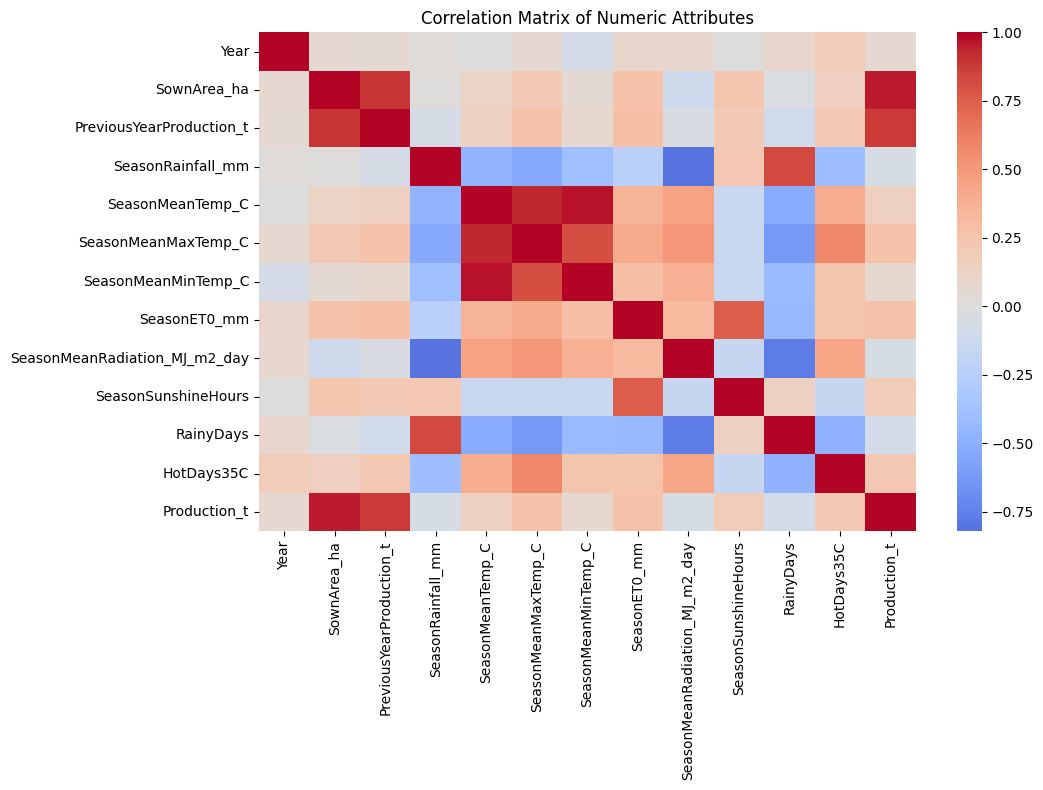

Correlation between sown area and production: 0.953


In [30]:
# Graph 5: Correlation between numeric columns.
plt.figure(figsize=(11, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numeric Attributes')
plt.tight_layout()
plt.show()

print('Correlation between sown area and production:',
      round(df['SownArea_ha'].corr(df['Production_t']), 3))

Production is generally larger where more land is sown, so cultivated area is expected to be a major predictor of total tonnes. This does not demonstrate a causal effect from any individual weather variable. Large districts may dominate average errors, so also inspect season- and district-specific errors. Correlated weather columns need cautious interpretation.

## 5. Data Preperation and Splitting


In [31]:
TARGET = 'Production_t'
features = [col for col in df.columns if col != TARGET]
categorical_columns = ['District','Season']
numeric_columns = [col for col in features if col not in categorical_columns]
train = df[df['Year'] <= 2019].copy()
valid = df[df['Year'].between(2020, 2021)].copy()
test = df[df['Year'].between(2022, 2023)].copy()
if min(len(train),len(valid),len(test)) == 0:
    raise ValueError('Expected non-empty training, validation and test year periods.')

def prepare_ensemble(train_data, other_data):
    """One-hot encoding and medians fitted using TRAINING observations only."""
    X_a = pd.get_dummies(train_data[features], columns=categorical_columns, dtype=int)
    X_b = pd.get_dummies(other_data[features], columns=categorical_columns, dtype=int)
    X_b = X_b.reindex(columns=X_a.columns, fill_value=0)
    medians = X_a.median(numeric_only=True)
    return X_a.fillna(medians), X_b.fillna(medians), medians

def prepare_ebm(train_data, other_data):
    """Retain native categories; use only TRAINING medians for missing numerics."""
    X_a = train_data[features].copy()
    X_b = other_data[features].copy()
    medians = X_a[numeric_columns].median()
    X_a[numeric_columns] = X_a[numeric_columns].fillna(medians)
    X_b[numeric_columns] = X_b[numeric_columns].fillna(medians)
    for col in categorical_columns:
        X_a[col] = X_a[col].fillna('Unknown').astype(str)
        X_b[col] = X_b[col].fillna('Unknown').astype(str)
    return X_a, X_b, medians

X_train, X_valid, train_medians = prepare_ensemble(train, valid)
X_ebm_train, X_ebm_valid, ebm_initial_medians = prepare_ebm(train, valid)
y_train, y_valid, y_test = train[TARGET], valid[TARGET], test[TARGET]
print('Training:', len(train), '| Validation:', len(valid), '| Unseen testing:', len(test))
print('One-hot inputs:', X_train.shape[1], '| EBM native inputs:', X_ebm_train.shape[1])
print('Categorical columns for EBM:', categorical_columns)

Training: 464 | Validation: 98 | Unseen testing: 98
One-hot inputs: 39 | EBM native inputs: 14
Categorical columns for EBM: ['District', 'Season']


## 6. Why Select Explainable Boosting Machine

Random Forest averages decision trees; XGBoost, CatBoost and LightGBM are boosted tree ensembles. EBM instead exposes an additive prediction comprising a baseline plus learned per-feature terms (and any enabled interactions). The EBM implementation here focuses on direct model explanations and does not claim calibrated prediction intervals.

In [32]:
# All FIVE models enter the same comparison and tuning pipeline.
def create_ebm(settings=None):
    settings = dict(settings or {})
    return ExplainableBoostingRegressor(
        random_state=RANDOM_SEED,
        n_jobs=2,
        outer_bags=2,
        max_rounds=800,
        validation_size=0.15,
        **settings
    )

models = {
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=10, min_samples_leaf=2, random_state=RANDOM_SEED, n_jobs=2),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, objective='reg:squarederror', random_state=RANDOM_SEED, n_jobs=2),
    'CatBoost': CatBoostRegressor(iterations=200, depth=4, learning_rate=0.05, loss_function='RMSE', verbose=False, random_seed=RANDOM_SEED, thread_count=2),
    'LightGBM': LGBMRegressor(n_estimators=200, num_leaves=15, learning_rate=0.05, min_child_samples=15, random_state=RANDOM_SEED, verbosity=-1, n_jobs=2),
    'EBM': create_ebm({'learning_rate': 0.04, 'max_leaves': 2, 'interactions': 0})
}
print('All five models:', list(models.keys()))

All five models: ['Random Forest', 'XGBoost', 'CatBoost', 'LightGBM', 'EBM']


## 7. Initial Training and Validation Comparison
Fit each model on the same training years, then compare MAE, RMSE and R² on 2020–2021. MAE/RMSE have units of tonnes. Lower MAE and RMSE are better; higher R² is better.

,Model,Validation MAE (tonnes),Validation RMSE (tonnes),Validation R²
1,XGBoost,10735.36,17565.24,0.98
2,CatBoost,12406.26,20181.38,0.97
3,LightGBM,12584.11,23953.21,0.95
0,Random Forest,13627.84,24069.54,0.95
4,EBM,16054.56,25734.30,0.95


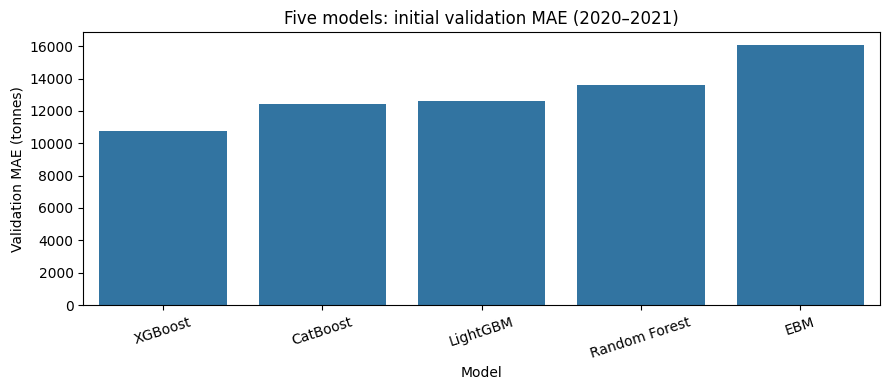

Initial lowest validation MAE: XGBoost


In [33]:
initial_rows = []
for name, model in models.items():
    X_a, X_b = (X_ebm_train, X_ebm_valid) if name == 'EBM' else (X_train, X_valid)
    fitted = create_ebm({'learning_rate': 0.04, 'max_leaves': 2, 'interactions': 0}) if name == 'EBM' else clone(model)
    fitted.fit(X_a, y_train)
    p = fitted.predict(X_b)
    initial_rows.append([name, mean_absolute_error(y_valid,p), np.sqrt(mean_squared_error(y_valid,p)), r2_score(y_valid,p)])
initial_table = pd.DataFrame(initial_rows, columns=['Model','Validation MAE (tonnes)','Validation RMSE (tonnes)','Validation R²']).sort_values('Validation MAE (tonnes)')
display(initial_table.round(2))
plt.figure(figsize=(9,4)); sns.barplot(data=initial_table,x='Model',y='Validation MAE (tonnes)')
plt.xticks(rotation=18);plt.title('Five models: initial validation MAE (2020–2021)');plt.tight_layout();plt.show()
print('Initial lowest validation MAE:', initial_table.iloc[0]['Model'])

The table above is a first comparison before hyperparameter tuning. The smallest validation MAE(10735.36 by XGBoost) indicates the lowest average prediction error on the 2020–2021 validation records.

## 8. Hyperparameter Tuning
Chronological expanding folds: **train ≤2015 → validate 2016–17**; **train ≤2017 → validate 2018–19**; **train ≤2019 → validate 2020–21**.


In [34]:
# Hyperparameter grids for ALL FIVE models.
previous_parameters = {
    'Random Forest': {'n_estimators':250,'max_depth':14,'min_samples_leaf':2},
    'XGBoost': {'n_estimators':200,'max_depth':5,'learning_rate':0.10},
    'CatBoost': {'iterations':200,'depth':6,'learning_rate':0.10},
    'LightGBM': {'n_estimators':200,'num_leaves':15,'learning_rate':0.05,'min_child_samples':10},
    'EBM': {'learning_rate':0.04,'max_leaves':2,'interactions':0}
}
parameter_grids = {
    'Random Forest': {'n_estimators':[150,300],'max_depth':[10,None],'min_samples_leaf':[1,3],'max_features':[0.8,1.0]},
    'XGBoost': {'n_estimators':[200,400],'max_depth':[3,5],'learning_rate':[0.03,0.10],'subsample':[0.8,1.0]},
    'CatBoost': {'iterations':[200,500],'depth':[4,6],'learning_rate':[0.03,0.10],'l2_leaf_reg':[3,6]},
    'LightGBM': {'n_estimators':[200,450],'num_leaves':[15,31],'learning_rate':[0.03,0.08],'min_child_samples':[10,25]},
    'EBM': {'learning_rate':[0.02,0.05],'max_leaves':[2,3],'interactions':[0,2]}
}
fold_years = [(2015,2016,2017),(2017,2018,2019),(2019,2020,2021)]
fold_data, ebm_fold_data = [], []
for training_end,validation_start,validation_end in fold_years:
    fold_train = df[df['Year']<=training_end]
    fold_valid = df[df['Year'].between(validation_start,validation_end)]
    Xa,Xb,_ = prepare_ensemble(fold_train,fold_valid)
    Ea,Eb,_ = prepare_ebm(fold_train,fold_valid)
    fold_data.append((Xa,fold_train[TARGET],Xb,fold_valid[TARGET]))
    ebm_fold_data.append((Ea,fold_train[TARGET],Eb,fold_valid[TARGET]))
print('Prepared',len(fold_years),'chronological validation folds. Final test years not used.')

Prepared 3 chronological validation folds. Final test years not used.


In [35]:
# Compare each candidate by average validation MAE across all three time folds.
best_parameters, tuning_rows, ebm_candidate_rows = {}, [], []
for name in models:
    candidates = [previous_parameters[name]] + [p for p in ParameterGrid(parameter_grids[name]) if p != previous_parameters[name]]
    all_folds = ebm_fold_data if name == 'EBM' else fold_data
    best_mae, best_settings, baseline_mae = float('inf'), None, None
    for number, params in enumerate(candidates):
        errors = []
        for X_a,y_a,X_b,y_b in all_folds:
            candidate = create_ebm(params) if name=='EBM' else clone(models[name]).set_params(**params)
            candidate.fit(X_a,y_a)
            errors.append(mean_absolute_error(y_b,candidate.predict(X_b)))
        mean_mae = float(np.mean(errors))
        if number == 0: baseline_mae = mean_mae
        if mean_mae < best_mae: best_mae, best_settings = mean_mae, dict(params)
        if name == 'EBM':
            ebm_candidate_rows.append({**params,'CV MAE (tonnes)':mean_mae,'Fold MAEs (tonnes)':str([round(x,1) for x in errors])})
    best_parameters[name] = best_settings
    tuning_rows.append([name,baseline_mae,best_mae,baseline_mae-best_mae,str(best_settings)])
    print(name,': evaluated',len(candidates),'parameter combinations across three folds.')
validation_table = pd.DataFrame(tuning_rows,columns=['Model','Baseline CV MAE','Tuned CV MAE','Improvement (tonnes)','Best parameters']).sort_values('Tuned CV MAE').reset_index(drop=True)
ebm_tuning_table = pd.DataFrame(ebm_candidate_rows).sort_values('CV MAE (tonnes)').reset_index(drop=True)
selected_model = validation_table.iloc[0]['Model']  # Select BEFORE inspecting 2022–23.
display(validation_table.round(2))
print('Model selected by chronological validation:', selected_model)
print('Best EBM settings:', best_parameters['EBM'])
display(ebm_tuning_table.head(8).round(2))

Random Forest : evaluated 17 parameter combinations across three folds.
XGBoost : evaluated 17 parameter combinations across three folds.
CatBoost : evaluated 17 parameter combinations across three folds.
LightGBM : evaluated 17 parameter combinations across three folds.
EBM : evaluated 9 parameter combinations across three folds.


,Model,Baseline CV MAE,Tuned CV MAE,Improvement (tonnes),Best parameters
0,XGBoost,11613.25,11439.53,173.72,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
1,LightGBM,11795.19,11602.43,192.76,"{'learning_rate': 0.08, 'min_child_samples': 1..."
2,CatBoost,13130.75,12461.23,669.52,"{'depth': 4, 'iterations': 500, 'l2_leaf_reg':..."
3,Random Forest,12682.24,12477.69,204.55,"{'max_depth': None, 'max_features': 1.0, 'min_..."
4,EBM,20018.27,19310.48,707.79,"{'interactions': 2, 'learning_rate': 0.02, 'ma..."


Model selected by chronological validation: XGBoost
Best EBM settings: {'interactions': 2, 'learning_rate': 0.02, 'max_leaves': 2}


,learning_rate,max_leaves,interactions,CV MAE (tonnes),Fold MAEs (tonnes)
0,0.02,2,2,19310.48,"[23245.6, 20009.5, 14676.4]"
1,0.05,2,2,19622.32,"[23623.0, 19761.4, 15482.5]"
2,0.02,2,0,19747.18,"[23327.8, 20124.5, 15789.2]"
3,0.05,2,0,20002.18,"[23775.3, 20088.0, 16143.2]"
4,0.04,2,0,20018.27,"[23874.4, 20125.9, 16054.6]"
5,0.02,3,2,23371.89,"[29624.3, 23622.2, 16869.2]"
6,0.05,3,2,23735.28,"[30307.1, 23437.2, 17461.6]"
7,0.02,3,0,23813.35,"[29753.3, 23817.4, 17869.4]"


Hyperparameter tuning improved the performance of all five models across three chronological validation periods. XGBoost performed best, achieving the lowest MAE of 11,439.53 tonnes. EBM improved from 20,018.27 to 19,310.48 tonnes, with the best settings of learning rate 0.02, max leaves 2, and 2 interactions. However, EBM still had a higher prediction error than the other models, indicating that XGBoost was more accurate during validation.

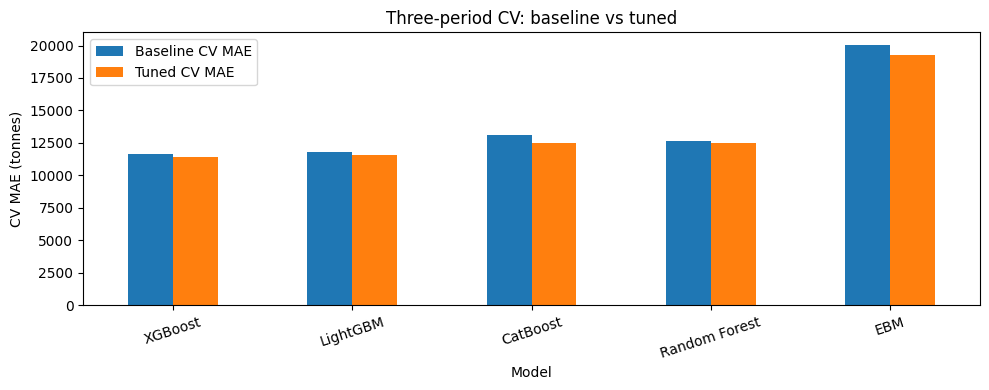

Lower tuned MAE means the selected settings gave smaller validation errors across three historical periods.


In [36]:
compare_cv = validation_table.set_index('Model')[['Baseline CV MAE','Tuned CV MAE']]
compare_cv.plot(kind='bar',figsize=(10,4));plt.ylabel('CV MAE (tonnes)');plt.title('Three-period CV: baseline vs tuned');plt.xticks(rotation=18);plt.tight_layout();plt.show()
print('Lower tuned MAE means the selected settings gave smaller validation errors across three historical periods.')

The graph shows that hyperparameter tuning reduced prediction errors for all five models across three validation periods. XGBoost achieved the lowest MAE (11,439.53 tonnes), making it the best-performing model during validation. EBM also improved after tuning, but its MAE remained the highest at 19,310.48 tonnes. Overall, tuning improved all models, although the improvement was relatively small.

## 9. Evaluation on Unseen 2022–2023

Selection based on validation: XGBoost
Lowest observed test MAE (report only; do not re-select): Random Forest


,Model,Test MAE (tonnes),Test RMSE (tonnes),Test R²
0,Random Forest,23945.11,41249.95,0.76
1,CatBoost,25742.12,44288.15,0.73
2,XGBoost,25882.50,42527.50,0.75
3,LightGBM,26220.02,43684.44,0.73
4,EBM,27667.97,43429.50,0.74


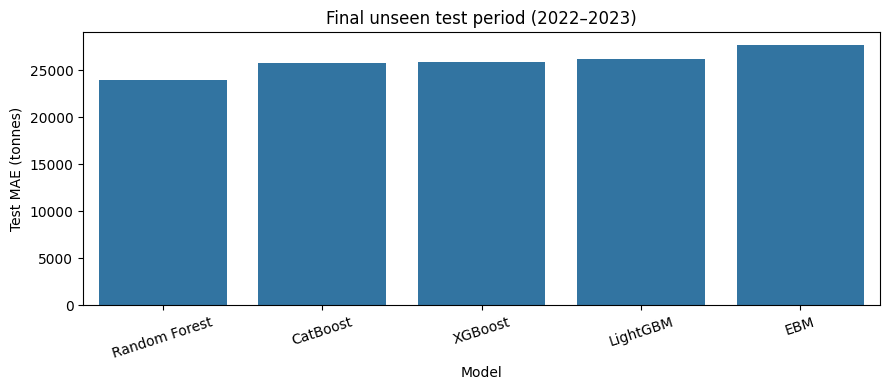

In [37]:
# The 2022–2023 observations are held out for the final evaluation only.
train_final = df[df['Year']<=2021].copy()
y_final = train_final[TARGET]
X_final,X_test_final,final_medians = prepare_ensemble(train_final,test)
X_ebm_final,X_ebm_test,ebm_final_medians = prepare_ebm(train_final,test)
trained_models, predictions, test_rows = {}, {}, []

for name in models:
    candidate = create_ebm(best_parameters[name]) if name=='EBM' else clone(models[name]).set_params(**best_parameters[name])
    fit_x, test_x = (X_ebm_final,X_ebm_test) if name=='EBM' else (X_final,X_test_final)
    candidate.fit(fit_x,y_final)
    p = candidate.predict(test_x)
    trained_models[name], predictions[name] = candidate, np.asarray(p)
    test_rows.append([name,mean_absolute_error(y_test,p),np.sqrt(mean_squared_error(y_test,p)),r2_score(y_test,p)])

test_table = pd.DataFrame(test_rows,columns=['Model','Test MAE (tonnes)','Test RMSE (tonnes)','Test R²']).sort_values('Test MAE (tonnes)').reset_index(drop=True)

print('Selection based on validation:',selected_model)
print('Lowest observed test MAE (report only; do not re-select):',test_table.iloc[0]['Model'])

display(test_table.round(2))
fig,ax=plt.subplots(figsize=(9,4));sns.barplot(data=test_table,x='Model',y='Test MAE (tonnes)',ax=ax)
ax.set_title('Final unseen test period (2022–2023)');ax.tick_params(axis='x',rotation=18);plt.tight_layout();plt.show()

Average absolute error by year:


Year,2022,2023
Model,,
CatBoost,36454.9,15029.4
EBM,37606.2,17729.7
LightGBM,34320.4,18119.7
Random Forest,33019.5,14870.8
XGBoost,34972.7,16792.3


Average absolute error by season:


Season,Maha,Yala
Model,,
CatBoost,33188.4,17985.6
EBM,36834.4,18119.6
LightGBM,34413.3,17685.3
Random Forest,31281.4,16303.1
XGBoost,32388.1,19105.9


EBM district-level errors (small groups need caution):


,count,mean
District,,
Anuradhapura,4,91497.8
Ampara,4,89914.2
Polonnaruwa,4,66147.4
Batticaloa,4,52244.2
Kurunegala,4,39830.8
Trincomalee,4,34977.4
Hambantota,4,26521.7
Puttalam,4,24506.8
Moneragala,4,24190.8


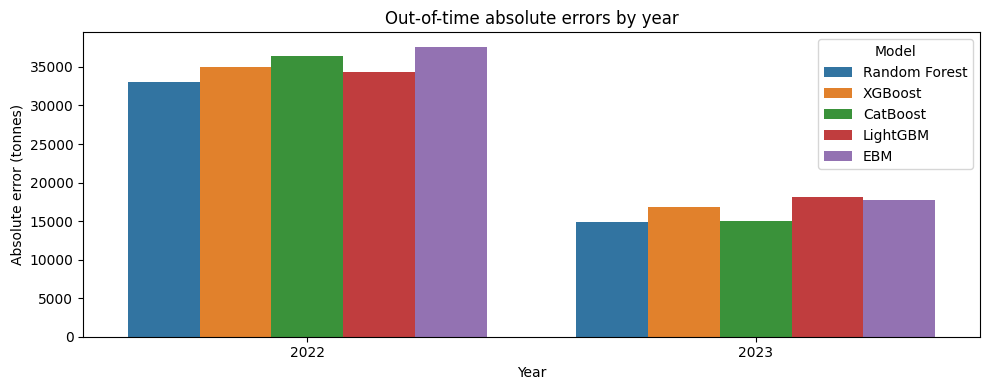

In [38]:
# Error differences by year, season and district reveal possible reliability gaps.
error_rows=[]
for name,p in predictions.items():
    temp=test[['Year','Season','District']].copy()
    temp['Model']=name
    temp['Absolute error (tonnes)']=np.abs(y_test.to_numpy()-p)
    error_rows.append(temp)
errors_by_group=pd.concat(error_rows,ignore_index=True)
print('Average absolute error by year:')
display(errors_by_group.groupby(['Model','Year'])['Absolute error (tonnes)'].mean().unstack().round(1))
print('Average absolute error by season:')
display(errors_by_group.groupby(['Model','Season'])['Absolute error (tonnes)'].mean().unstack().round(1))
print('EBM district-level errors (small groups need caution):')
display(errors_by_group[errors_by_group['Model']=='EBM'].groupby('District')['Absolute error (tonnes)'].agg(['count','mean']).sort_values('mean',ascending=False).head(10).round(1))
fig,ax=plt.subplots(figsize=(10,4))
sns.barplot(data=errors_by_group,x='Year',y='Absolute error (tonnes)',hue='Model',errorbar=None,ax=ax)
ax.set_title('Out-of-time absolute errors by year');plt.tight_layout();plt.show()

All five models were evaluated using unseen 2022–2023 data. Random Forest performed best, with the lowest MAE of 23,945.1 tonnes. EBM achieved an MAE of 27,668.0 tonnes, RMSE of 43,429.5 tonnes, and R² of 0.736, showing reasonable predictive performance. EBM's errors were higher in 2022 and during the Maha season, indicating differences in prediction reliability across years and seasons.

## 10. Model Selection

In [39]:
winner_mae = float(validation_table.loc[validation_table['Model']==selected_model,'Tuned CV MAE'].iloc[0])
print(f'Validation-selected model: {selected_model} (CV MAE: {winner_mae:,.1f} tonnes).')
print('Observed lowest held-out-test error:',test_table.iloc[0]['Model'])

Validation-selected model: XGBoost (CV MAE: 11,439.5 tonnes).
Observed lowest held-out-test error: Random Forest


After evaluating all five models using three chronological validation periods, XGBoost achieved the lowest MAE of 11,439.53 tonnes, making it the best-performing model during validation.

## 11. SHAP for model explainability
SHAP estimates how much each input feature raises or lowers a prediction compared with the model's average prediction. I have use the model selected using validation (XGBoost), not the model that happened to get the best test score.

This will show:
- Global importance: which features influence the model's predictions most overall.
- Beeswarm plot: whether higher/lower feature values tend to push predictions up or down.
- Waterfall plot: why the model made one district-season prediction.

SHAP describes the model's behaviour. It does not prove that changing rainfall or area will cause production to change.

Explained benchmark: XGBoost


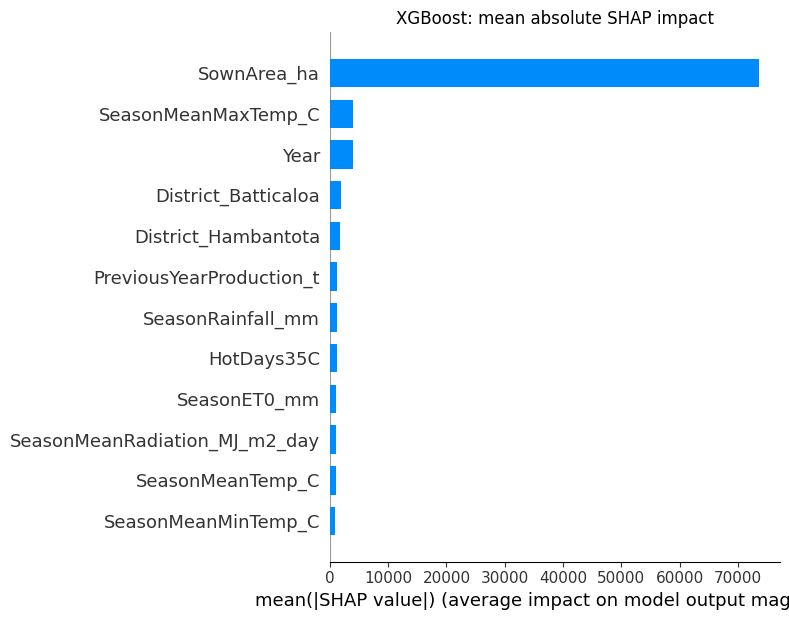

,Average SHAP impact (tonnes)
SownArea_ha,73524.796875
SeasonMeanMaxTemp_C,4049.000000
Year,4045.899902
District_Batticaloa,1975.800049
District_Hambantota,1682.500000
PreviousYearProduction_t,1280.300049
SeasonRainfall_mm,1254.199951
HotDays35C,1216.800049
SeasonET0_mm,1118.500000
SeasonMeanRadiation_MJ_m2_day,1003.400024


In [40]:
import shap
benchmark_name='XGBoost'
tree_model = trained_models[benchmark_name]
shap_explainer = shap.TreeExplainer(tree_model)
shap_values = shap_explainer(X_test_final)
print('Explained benchmark:',benchmark_name)
shap.summary_plot(shap_values.values,X_test_final,plot_type='bar',max_display=12,show=False)
plt.title('XGBoost: mean absolute SHAP impact');plt.tight_layout();plt.show()
shap_importance = pd.Series(np.abs(shap_values.values).mean(axis=0),index=X_test_final.columns).sort_values(ascending=False)
display(shap_importance.head(10).to_frame('Average SHAP impact (tonnes)').round(1))

The SHAP results show that Sown Area is the most influential feature in predicting paddy production, with an average impact of 73,524.80 tonnes. Temperature and Year are the next most important factors, followed by District and Previous Year Production. Rainfall and other weather conditions have smaller influences. Overall, the results suggest that cultivated area is the main factor influencing XGBoost predictions, while weather and location also contribute.

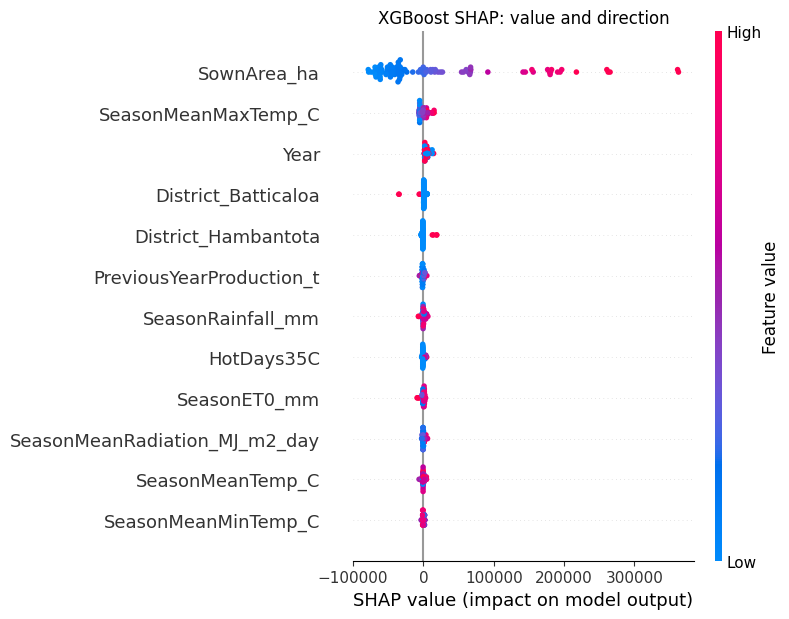

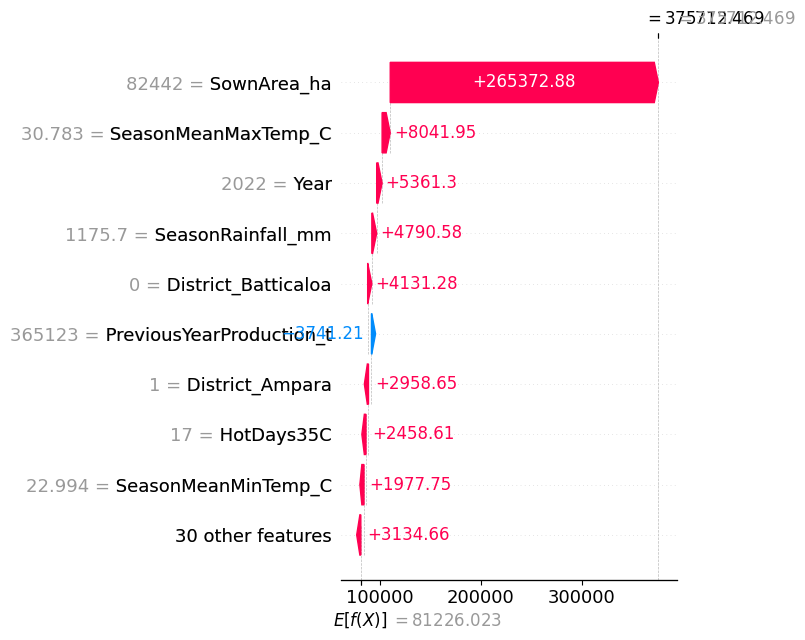

Example: {'District': 'Ampara', 'Season': 'Maha', 'Year': 2022}
Actual tonnes: 221529.0 | XGBoost predicted tonnes: 375712.40625
Most influential SHAP feature overall: SownArea_ha


In [41]:
# Direction and local explanation for one held-out observation.
sample_index=0
shap.summary_plot(shap_values.values,X_test_final,max_display=12,show=False)
plt.title('XGBoost SHAP: value and direction');plt.tight_layout();plt.show()
shap.plots.waterfall(shap_values[sample_index],max_display=10,show=False)
plt.tight_layout();plt.show()
print('Example:',test.iloc[sample_index][['District','Season','Year']].to_dict())
print('Actual tonnes:',float(y_test.iloc[sample_index]), '| XGBoost predicted tonnes:',float(predictions[benchmark_name][sample_index]))
print('Most influential SHAP feature overall:',shap_importance.index[0])

The SHAP summary plot shows that Sown Area is the most influential feature in XGBoost predictions. Larger cultivated areas generally increase predicted paddy production, while temperature, year, and rainfall have smaller effects.

For the selected prediction, XGBoost estimated approximately 375,715 tonnes, compared with an average baseline of 81,226 tonnes. Sown Area contributed the most (+265,373 tonnes), followed by temperature, year, and rainfall. Previous Year Production slightly reduced the prediction. Overall, SHAP clearly shows how different features influence the predicted harvest.

## 12. LIME for model explainability
LIME makes small changes around one test observation, asks the model for predictions, and fits a simple local explanation. This helps us understand *one prediction*, rather than the whole model.

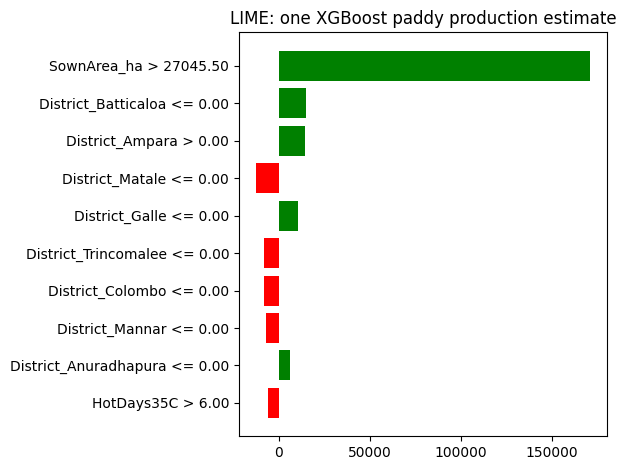

,Feature condition,Local effect (tonnes)
0,SownArea_ha > 27045.50,171274.9
1,District_Batticaloa <= 0.00,15149.7
2,District_Ampara > 0.00,14301.1
3,District_Matale <= 0.00,-12537.6
4,District_Galle <= 0.00,10548.2
5,District_Trincomalee <= 0.00,-8209.4
6,District_Colombo <= 0.00,-8164.0
7,District_Mannar <= 0.00,-6900.0
8,District_Anuradhapura <= 0.00,6527.6
9,HotDays35C > 6.00,-5996.2


LIME local explanation fit R²: 0.75


In [42]:
from lime.lime_tabular import LimeTabularExplainer
lime_explainer = LimeTabularExplainer(training_data=X_final.to_numpy(dtype=float),feature_names=X_final.columns.tolist(),mode='regression',discretize_continuous=True,random_state=42)

def predict_for_lime(array):
    # Recreate names because XGBoost expects the same feature order.
    return tree_model.predict(pd.DataFrame(array,columns=X_final.columns))

lime_example = lime_explainer.explain_instance(X_test_final.iloc[sample_index].to_numpy(dtype=float),predict_for_lime,num_features=10,num_samples=1500)
lime_example.as_pyplot_figure();plt.title('LIME: one XGBoost paddy production estimate');plt.tight_layout();plt.show()
display(pd.DataFrame(lime_example.as_list(),columns=['Feature condition','Local effect (tonnes)']).round(1))
print('LIME local explanation fit R²:',round(lime_example.score,3))

The LIME results show that Sown Area is the most influential factor in this XGBoost prediction, increasing the estimated paddy production by approximately 171,275 tonnes. District-related features also affect the prediction, while having more than six extremely hot days reduces it by around 5,996 tonnes. Overall, LIME shows how different agricultural, location, and weather factors increase or decrease the predicted harvest for this specific example.

## 13. EBM for model Explainability: Global and Local Feature Effects
One of the main advantages of Explainable Boosting Machine (EBM) is that we can understand how it makes predictions. Unlike SHAP and LIME, which explain predictions after training, EBM is designed to be explainable.

**Global explainability** shows which features have the greatest influence on paddy production predictions. Feature effect plots help us understand how changes in factors such as rainfall, temperature, and cultivated area affect the predicted harvest.

**Local explainability** shows how individual features contribute to a specific district's seasonal paddy production prediction. This helps us understand not only the predicted harvest but also the reasons behind it.

,Term,Importance (model units)
3,SownArea_ha,53517.13
0,District,12020.53
7,SeasonMeanMaxTemp_C,7346.11
4,PreviousYearProduction_t,7094.90
5,SeasonRainfall_mm,4651.93
1,Year,2942.56
13,HotDays35C,2782.98
12,RainyDays,2583.06
10,SeasonMeanRadiation_MJ_m2_day,2518.34
9,SeasonET0_mm,2288.17


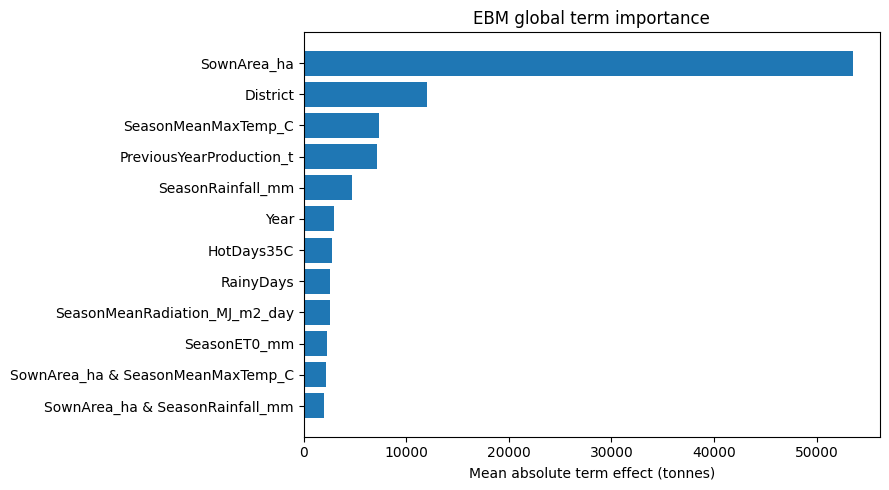

Most influential EBM term: SownArea_ha
Importance is association within the model, NOT causal influence.


In [43]:
ebm_model=trained_models['EBM']
ebmi=pd.DataFrame({'Term':ebm_model.term_names_,'Importance (model units)':ebm_model.term_importances()}).sort_values('Importance (model units)',ascending=False)
display(ebmi.head(15).round(2))
plt.figure(figsize=(9,5));visible=ebmi.head(12).iloc[::-1]
plt.barh(visible['Term'],visible['Importance (model units)'])
plt.title('EBM global term importance');plt.xlabel('Mean absolute term effect (tonnes)');plt.tight_layout();plt.show()
print('Most influential EBM term:',ebmi.iloc[0]['Term'])
print('Importance is association within the model, NOT causal influence.')

Sown Area is the most influential feature in EBM predictions, with an importance of 53,517 tonnes, followed by District, Maximum Temperature, Previous Year Production, and Rainfall. This shows that cultivated area has the greatest influence on predicted paddy production.

District / Season / Year: {'District': 'Ampara', 'Season': 'Maha', 'Year': 2022}
Baseline 81,000.1 + feature effects 313,730.2 = 394,730.2 tonnes
EBM prediction 394,730.2; actual production 221,529.0; error +173,201.2 tonnes


,Term,Contribution (tonnes)
3,SownArea_ha,229128.6
0,District,52854.5
4,PreviousYearProduction_t,-29399.8
15,SownArea_ha & SeasonMeanMaxTemp_C,17790.6
13,HotDays35C,10149.0
5,SeasonRainfall_mm,7356.8
1,Year,6674.3
7,SeasonMeanMaxTemp_C,6645.1
14,SownArea_ha & SeasonRainfall_mm,6457.9
9,SeasonET0_mm,3939.1


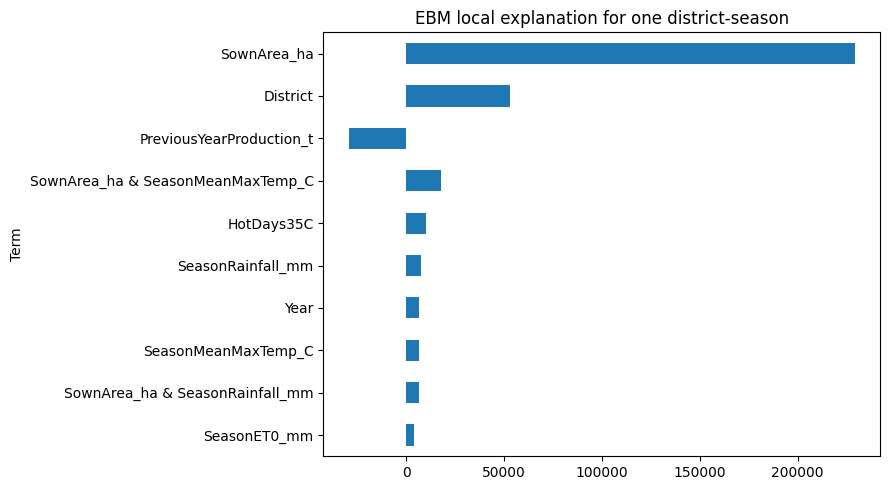

In [44]:
# EBM additive prediction breakdown for one held-out record.
sample = X_ebm_test.iloc[[sample_index]]
term_contributions=np.asarray(ebm_model.eval_terms(sample))[0]
base = float(np.asarray(ebm_model.intercept_).reshape(-1)[0])
local_table=pd.DataFrame({'Term':ebm_model.term_names_,'Contribution (tonnes)':term_contributions}).sort_values('Contribution (tonnes)',key=abs,ascending=False)
actual=float(y_test.iloc[sample_index]); predicted=float(ebm_model.predict(sample)[0])
print('District / Season / Year:',test.iloc[sample_index][['District','Season','Year']].to_dict())
print(f'Baseline {base:,.1f} + feature effects {term_contributions.sum():,.1f} = {base+term_contributions.sum():,.1f} tonnes')
print(f'EBM prediction {predicted:,.1f}; actual production {actual:,.1f}; error {predicted-actual:+,.1f} tonnes')
if not np.isclose(base+term_contributions.sum(),predicted,rtol=1e-5,atol=1.0):
    print('Note: check link function or model version for term-sum consistency.')
display(local_table.head(12).round(1))
plt.figure(figsize=(9,5));local_table.head(10).iloc[::-1].plot.barh(x='Term',y='Contribution (tonnes)',legend=False,ax=plt.gca())
plt.title('EBM local explanation for one district-season');plt.tight_layout();plt.show()

For Ampara district, Maha season 2022, EBM predicted approximately 394,730 tonnes, while actual production was 221,529 tonnes, an overestimation of around 173,200 tonnes. Sown Area contributed the most to increasing the prediction, while Previous Year Production reduced it. This shows how EBM explains individual predictions, while also highlighting possible prediction errors.

## 14. Discussion
**Data quality:** The agricultural source has been identified as Sri Lanka DCS, but individual workbook rows are not yet traced to original tables; verify weather-variable provenance, aggregation method and any historical revisions. Missing previous-year production measurements are imputed using earlier training observations only. District and season representation may differ.

**Model limitations:** Production in tonnes is strongly linked to cultivated area, so high performance does not by itself establish insight into individual weather effects. End-of-season observed rainfall/temperature cannot be assumed available for **pre-planting forecasts**. Unseen 2022–2023 errors may be much larger than validation errors due to year-to-year changes. Only two final test years are available; independent future years are needed before deployment.

**Risks of bias or unfairness:** Compare errors by district, season and year. Larger districts can dominate average tonne errors. Regions with fewer examples may be less reliably represented; the reported figures do not prove equity across locations.

**Improvement opportunities:** Verify DCS table links and weather source, include fully observed additional years, test predictions without previous-year production as a sensitivity study, compare yield per hectare, and evaluate future external years. EBM can aid interpretation, but shape functions are not evidence of causal effects.

## 15. Save to Pickle File

The saved bundle goes into **`models/`** at the repository root. Run the notebook from the project root or the `notebooks/` directory. In Colab, download the generated `.pkl` and upload it to your GitHub repository's `models/` folder.


In [ ]:
import pickle
import tempfile
import sklearn, xgboost, catboost, lightgbm
import importlib.metadata

# Save XGBoost as native JSON bytes inside the single pickle.
# Its Python-pickled native memory snapshot can fail across environments.
with tempfile.TemporaryDirectory() as xgb_folder:
    xgb_path = Path(xgb_folder) / 'xgboost.json'
    trained_models['XGBoost'].save_model(str(xgb_path))
    xgb_json = xgb_path.read_bytes()

portable_models = dict(trained_models)
portable_models['XGBoost'] = None  # Reconstructed from xgboost_native_json when loading
model_bundle = {
    'models': portable_models,                  # Random Forest, XGBoost, CatBoost, LightGBM, EBM
    'xgboost_native_json': xgb_json,
    'library_versions': {
        'scikit-learn': sklearn.__version__,
        'xgboost': xgboost.__version__,
        'catboost': catboost.__version__,
        'lightgbm': lightgbm.__version__,
        'interpret-core': importlib.metadata.version('interpret-core'),
    },
    'features': features,                      # Raw feature names, target excluded
    'categorical_columns': categorical_columns,
    'numeric_columns': numeric_columns,
    'encoded_columns': X_final.columns.tolist(),
    'train_medians': final_medians.to_dict(),
    'ebm_numeric_medians': ebm_final_medians.to_dict(),
    'districts': sorted(df['District'].dropna().unique().tolist()),
    'seasons': sorted(df['Season'].dropna().unique().tolist()),
    'numeric_defaults': train_final[numeric_columns].median().to_dict(),
    'trained_through_year': int(train_final['Year'].max()),
    'selected_by_validation': selected_model,
    'validation_results': validation_table.to_dict(orient='records'),
    'test_results': test_table.to_dict(orient='records'),
    'ebm_global_importance': ebmi.to_dict(orient='records')
}
# Keep one trained-model bundle in the repository models/ folder.
# Notebook may run from repo root, notebooks/, or Colab (/content).
model_dir = Path('../models') if Path.cwd().name.lower() == 'notebooks' else Path('models')
model_dir.mkdir(parents=True, exist_ok=True)
pickle_filename = model_dir / 'paddy_production_all_five_models_ebm.pkl'
with open(pickle_filename,'wb') as f: pickle.dump(model_bundle,f,protocol=pickle.HIGHEST_PROTOCOL)
print('Saved ONE pickle:',pickle_filename)
print('Models:',list(model_bundle['models'].keys()))

In [ ]:
# Verify that every loaded model matches the previously fitted one.
with open(pickle_filename,'rb') as f: loaded_bundle=pickle.load(f)
# Load XGBoost from its portable JSON stored inside the same pickle.
with tempfile.TemporaryDirectory() as xgb_folder:
    xgb_path = Path(xgb_folder) / 'xgboost.json'
    xgb_path.write_bytes(loaded_bundle['xgboost_native_json'])
    reloaded_xgb = XGBRegressor()
    reloaded_xgb.load_model(str(xgb_path))
loaded_bundle['models']['XGBoost'] = reloaded_xgb
example = test.iloc[[0]][features].copy()
encoded = pd.get_dummies(example,columns=categorical_columns,dtype=int)
X_new=encoded.reindex(columns=loaded_bundle['encoded_columns'],fill_value=0).fillna(loaded_bundle['train_medians'])
X_new_ebm=example.copy()
for col in loaded_bundle['numeric_columns']:
    X_new_ebm[col]=X_new_ebm[col].fillna(loaded_bundle['ebm_numeric_medians'][col])
for col in loaded_bundle['categorical_columns']:
    X_new_ebm[col]=X_new_ebm[col].fillna('Unknown').astype(str)
for name, model in loaded_bundle['models'].items():
    xx = X_new_ebm if name=='EBM' else X_new
    restored = float(model.predict(xx)[0]); original = float(predictions[name][0])
    print(f'{name:14s}: fitted {original:,.2f} vs reloaded {restored:,.2f} tonnes')
    if not np.isclose(original,restored,rtol=1e-6,atol=0.05):
        raise ValueError(f'Pickle reload changed {name} prediction.')
print('Verified: all FIVE fitted models restored from ONE pickle file.')